# LASSER study: multi-split evaluation, controls, ablations and analysis

This notebook runs the full experiment set for the paper and analyses it.

| Tier | Arms | Splits | Runs |
|---|---|---|---|
| Core | `GEARS`, `LASSER` | 1–5 | 10 |
| Controls | `GEARS-kNN8` (density-matched Pearson graph), `LASSER-random` (learned edges rewired at random, same in-degrees and weights) | 1–5 | 10 |
| Ablations | `LASSER-noS`, `LASSER-Eonly`, `LASSER-addonly`, `LASSER-embinit`, `LASSER-m2`, `LASSER-m10` | 1–3 | 18 |

**Kaggle settings:** Accelerator **GPU T4 x2**, **Internet on**.

**How to run.** Each run takes about 85 min. With two GPUs one Kaggle session (12 h) finishes about 14 runs, so the study needs **about 3 sessions**.

1. Use *Save Version → Save & Run All (Commit)*, so it runs in the background for up to 12 h. Workers stop taking new jobs before the time limit, and the analysis cells then run on whatever has finished.
2. For the next session, add the previous version's **output** as an input (*Add Input → Your Work → this notebook*) and set `RESUME_FROM` in cell 3 to its `study` folder. Finished jobs are skipped automatically.
3. Repeat until the status table shows every job done. The analysis cells (section B) can also be run alone, CPU only, on the final output.

## A. Setup and experiments

In [1]:
# 1. Dependencies (GEARS is vendored inside lasser/; matplotlib, scipy, pandas are preinstalled on Kaggle).
!pip install -q torch_geometric scanpy pytest

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 47.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 60.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.2/190.2 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.1/79.1 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.3/405.3 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.5/230.5 kB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 50.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 3.8 MB/s eta 0:00:00


In [2]:
# 2. Code: clone, then move the self-contained package next to the notebook.
REPO_URL = "https://github.com/LegendaryDarkKnight/LASSER"
REPO_DIR = "/kaggle/working/lasser-repo"
!rm -rf {REPO_DIR} /kaggle/working/lasser
!git clone -q {REPO_URL} {REPO_DIR}
!mv {REPO_DIR}/lasser /kaggle/working/lasser
!git -C {REPO_DIR} log -1 --oneline

f72d2b6 (HEAD -> main, origin/main, origin/HEAD) Including study


In [3]:
# 3. Settings. Edit RESUME_FROM in sessions 2, 3, ... (the previous version's output 'study' folder).
import os, shutil, time
T0 = time.time()                                   # session start, for the time budget
SESSION_HOURS = 11.5                               # Kaggle limit is 12 h; leave time for analysis + saving
ANALYSIS_RESERVE_HOURS = 0.5
STUDY_DIR = "/kaggle/working/study"                # saved as notebook output (runs, cache, tables, figures)
DATA_DIR = "/tmp/lasser_data"                      # NOT saved (several GB); re-downloaded each session
RESUME_FROM = None                                 # e.g. "/kaggle/input/lasser-study/study"
RUN_FULL_TESTS = False                             # True: also the dataset tests (~20 min)

os.makedirs(STUDY_DIR, exist_ok=True)
if RESUME_FROM:
    shutil.copytree(RESUME_FROM, STUDY_DIR, dirs_exist_ok=True)
    shutil.rmtree(os.path.join(STUDY_DIR, "claims"), ignore_errors=True)   # claims are per session
    print("resumed from", RESUME_FROM)
!nvidia-smi --query-gpu=index,name,memory.total --format=csv

index, name, memory.total [MiB]
0, Tesla T4, 15360 MiB
1, Tesla T4, 15360 MiB


In [4]:
# 4. Fast tests (seconds; no data): GEARS-printout parser, random-edge control, job table, analysis, figures.
!cd /kaggle/working && python -m pytest {REPO_DIR}/tests/test_05_parsing.py {REPO_DIR}/tests/test_06_study.py -q -p no:cacheprovider --tb=short
if RUN_FULL_TESTS:
    %env LASSER_DATA_DIR={DATA_DIR}
    %env LASSER_TEST_DIR=/tmp/lasser_tests
    !cd /kaggle/working && python -m pytest {REPO_DIR}/tests -m "not smoke" -q -p no:cacheprovider --tb=short 2>&1 | tail -n 30

...F.                                                                    [100%]
=================================== FAILURES ===================================
________________________ test_analysis_tables_and_stats ________________________
lasser-repo/tests/test_06_study.py:149: in test_analysis_tables_and_stats
    assert set(gg.gene_group) == {"isolated_in_A0", "connected_in_A0"}
E   AssertionError: assert {'isolated_in_A0'} == {'connected_i...olated_in_A0'}
E     
E     Extra items in the right set:
E     'connected_in_A0'
E     Use -v to get more diff
=============================== warnings summary ===============================
lasser-repo/tests/test_06_study.py::test_figures_render
  /usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:45: PyparsingDeprecationWarning: 'enablePackrat' deprecated - use 'enable_packrat'
    ParserElement.enablePackrat()

lasser-repo/tests/test_06_study.py: 25 warnings
  /usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pa

In [5]:
# 5. The experiment table (priority order: core, controls, ablations) and what is already done.
import pandas as pd
from lasser.study import ARM_DESCRIPTIONS, DEFAULT_PLAN, make_jobs, study_status, expected_minutes

BASE = dict(dataset="norman", split="simulation", epochs=20, device="cuda",
            data_dir=DATA_DIR, out_dir=f"{STUDY_DIR}/runs", cache_dir=f"{STUDY_DIR}/cache", repo_dir=REPO_DIR)
PLAN = DEFAULT_PLAN                                 # list of (arm, splits); edit to add or drop runs
jobs = make_jobs(PLAN, BASE)
display(pd.DataFrame([(a, ", ".join(map(str, s)), ARM_DESCRIPTIONS[a]) for a, s in PLAN],
                     columns=["arm", "splits", "what it tests"]))
status = study_status(jobs)
print(f"{int(status.done.sum())}/{len(status)} runs done; ~{expected_minutes(BASE['out_dir']):.0f} min per run")
status.pivot_table(index="arm", columns="seed", values="done", aggfunc="first").reindex([a for a, _ in PLAN])

,arm,splits,what it tests
0,GEARS,"1, 2, 3, 4, 5","GEARS, static Pearson co-expression graph (|r|..."
1,LASSER,"1, 2, 3, 4, 5",GEARS on the GSR-refined co-expression graph (...
2,GEARS-kNN8,"1, 2, 3, 4, 5","GEARS, Pearson top-8 neighbours without thresh..."
3,LASSER-random,"1, 2, 3, 4, 5",LASSER graph with every new edge rewired to a ...
4,LASSER-noS,"1, 2, 3",LASSER without the structure view (views E + R)
5,LASSER-Eonly,"1, 2, 3",LASSER with the expression view only
6,LASSER-addonly,"1, 2, 3",LASSER without removing A0 edges (r- = 0)
7,LASSER-embinit,"1, 2, 3",LASSER + gene embedding initialised from the p...
8,LASSER-m2,"1, 2, 3",LASSER with m+ = 2 new edges per gene
9,LASSER-m10,"1, 2, 3",LASSER with m+ = 10 new edges per gene


0/38 runs done; ~95 min per run


seed,1,2,3,4,5
arm,,,,,
GEARS,False,False,False,False,False
LASSER,False,False,False,False,False
GEARS-kNN8,False,False,False,False,False
LASSER-random,False,False,False,False,False
LASSER-noS,False,False,False,NaN,NaN
LASSER-Eonly,False,False,False,NaN,NaN
LASSER-addonly,False,False,False,NaN,NaN
LASSER-embinit,False,False,False,NaN,NaN
LASSER-m2,False,False,False,NaN,NaN


In [6]:
# 6. Download data and build every split and GEARS graph once (one subprocess, ~10 min the first time).
from lasser.study import prepare_data
if not study_status(jobs).done.all():
    prepare_data(jobs)

Saving new dataset pyg object at /tmp/lasser_data/norman/data_pyg/cell_graphs.pkl
Saving new splits at /tmp/lasser_data/norman/splits/norman_simulation_1_0.75.pkl
Saving new splits at /tmp/lasser_data/norman/splits/norman_simulation_2_0.75.pkl
Saving new splits at /tmp/lasser_data/norman/splits/norman_simulation_3_0.75.pkl
Saving new splits at /tmp/lasser_data/norman/splits/norman_simulation_4_0.75.pkl
Saving new splits at /tmp/lasser_data/norman/splits/norman_simulation_5_0.75.pkl


In [7]:
# 7. Run the remaining jobs: one worker process per GPU, progress printed every 10 min.
#    Workers stop taking jobs when the next one would pass the session budget.
from lasser.study import launch
budget = SESSION_HOURS - ANALYSIS_RESERVE_HOURS - (time.time() - T0) / 3600
if not study_status(jobs).done.all():
    status = launch(jobs, budget_hours=budget, poll_minutes=10)
status = study_status(jobs)
print(f"{int(status.done.sum())}/{len(status)} runs done")
fails = f"{BASE['out_dir']}/failures.csv"
if os.path.exists(fails):
    display(pd.read_csv(fails).tail(5))
status.pivot_table(index="arm", columns="seed", values="test_pearson_delta", aggfunc="first").reindex([a for a, _ in PLAN])

session 20261012-164720: 0/38 jobs already done, 38 to run on 2 GPU(s); ~95 min each -> ~30.1 h (budget 10.8 h)
worker 0: GPU 0, pid 127, log /kaggle/working/study/runs/logs/worker0_20261012-164720.log
worker 1: GPU 1, pid 136, log /kaggle/working/study/runs/logs/worker1_20261012-164720.log
[16:58] done 0/38 | running: GEARS_seed1, GEARS_seed2
[17:08] done 0/38 | running: GEARS_seed1, GEARS_seed2
[17:18] done 0/38 | running: GEARS_seed1, GEARS_seed2
[17:28] done 0/38 | running: GEARS_seed1, GEARS_seed2
[17:38] done 0/38 | running: GEARS_seed1, GEARS_seed2
[17:48] done 0/38 | running: GEARS_seed1, GEARS_seed2
[17:58] done 0/38 | running: GEARS_seed1, GEARS_seed2
[18:08] done 0/38 | running: GEARS_seed1, GEARS_seed2
[18:18] done 1/38 | running: GEARS_seed1, GEARS_seed3
[18:28] done 1/38 | running: GEARS_seed1, GEARS_seed3
[18:38] done 1/38 | running: GEARS_seed1, GEARS_seed3
[18:48] done 1/38 | running: GEARS_seed1, GEARS_seed3
[18:58] done 1/38 | running: GEARS_seed1, GEARS_seed3
[19:08

seed,1,2,3,4,5
arm,,,,,
GEARS,NaN,0.524159,0.547315,0.536181,0.523345
LASSER,0.490899,0.523485,0.551456,NaN,NaN
GEARS-kNN8,NaN,NaN,NaN,NaN,NaN
LASSER-random,NaN,NaN,NaN,NaN,NaN
LASSER-noS,NaN,NaN,NaN,NaN,NaN
LASSER-Eonly,NaN,NaN,NaN,NaN,NaN
LASSER-addonly,NaN,NaN,NaN,NaN,NaN
LASSER-embinit,NaN,NaN,NaN,NaN,NaN
LASSER-m2,NaN,NaN,NaN,NaN,NaN


## B. Analysis

Everything below reads the saved run folders, so it works on partial results and can be rerun alone (CPU) on a
previous version's output: set `STUDY_DIR` to that folder and run from here.

Metrics are eval.py's paper metrics (Roohani et al. 2024): Pearson Δ over all genes and over the top-20 DE genes,
MSE on the top-20 DE genes, normalised MSE (ratio of means, robust to tiny denominators) and the fraction of top-20
DE genes predicted in the wrong direction. Statistics:
- **Across splits** (the unit of replication): mean ± sd, paired *t*-test, Wilcoxon signed-rank (with 5 splits its
  smallest possible two-sided *p* is 0.0625), Holm correction across the comparisons in a table.
- **Across perturbations**: paired (split, perturbation) differences, share improved, Wilcoxon, and a 95 % CI from a
  bootstrap that resamples splits and then perturbations within splits.

In [8]:
# 8. Load results; reference baselines (no perturbation, additive) scored with the same eval.py functions.
import numpy as np
from lasser import analysis as A
from lasser import figures as F
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 250)

RESULTS_DIR, FIG_DIR = f"{STUDY_DIR}/results", f"{STUDY_DIR}/figures"
runs = A.load_runs(f"{STUDY_DIR}/runs")
long = A.metrics_long(runs)
H5AD = f"{DATA_DIR}/norman/perturb_processed.h5ad"
if os.path.exists(H5AD):
    long = pd.concat([long, A.paper_reference_baselines(runs, H5AD)], ignore_index=True)
else:
    print("no h5ad found; skipping the no-perturbation/additive baselines")
CORE = [a for a in ["GEARS", "LASSER", "GEARS-kNN8", "LASSER-random"] if a in set(runs.arm)]
REFS = [a for a in ["No-perturb", "Additive"] if a in set(long[long.family == "paper"].arm)]
ABL = [a for a in ["LASSER", "LASSER-noS", "LASSER-Eonly", "LASSER-addonly", "LASSER-embinit",
                   "LASSER-m2", "LASSER-m10"] if a in set(runs.arm)]
print(runs.groupby("arm").seed.apply(sorted))

arm
GEARS     [2, 3, 4, 5]
LASSER       [1, 2, 3]
Name: seed, dtype: object


In [9]:
# 9. Table 1: headline metrics, mean ± sd over splits (overall and per test subgroup).
SCOPES = ["overall"] + A.SUBGROUPS
t1 = A.summary_table(long, A.HEADLINE, scopes=["overall"], arms=REFS + CORE)
display(t1)
t1_sub = A.summary_table(long, ["pearson_delta", "mse_top20_de", "frac_opposite_top20_de"],
                         scopes=A.SUBGROUPS, arms=REFS + CORE)
display(t1_sub)

overall                                                                                                
                  pearson_delta pearson_delta_top20_de         mse_top20_de nmse_top20_de_ratio_of_means frac_opposite_top20_de
arm                                                                                                                            
No-perturb  0.000 ± 0.000 (n=5)    0.000 ± 0.000 (n=5)  0.466 ± 0.062 (n=5)          1.000 ± 0.000 (n=5)    0.000 ± 0.000 (n=5)
Additive    0.414 ± 0.025 (n=5)    0.447 ± 0.022 (n=5)  0.266 ± 0.064 (n=5)          0.564 ± 0.067 (n=5)    0.087 ± 0.011 (n=5)
GEARS       0.533 ± 0.011 (n=4)    0.646 ± 0.027 (n=4)  0.224 ± 0.070 (n=4)          0.464 ± 0.084 (n=4)    0.351 ± 0.021 (n=4)
LASSER      0.522 ± 0.030 (n=3)    0.640 ± 0.043 (n=3)  0.219 ± 0.031 (n=3)          0.465 ± 0.031 (n=3)    0.354 ± 0.017 (n=3)

unseen_single                                                      combo_seen0                                                      combo_seen1                                                      combo_seen2                       \
                  pearson_delta         mse_top20_de frac_opposite_top20_de        pearson_delta         mse_top20_de frac_opposite_top20_de        pearson_delta         mse_top20_de frac_opposite_top20_de        pearson_delta         mse_top20_de   
arm                                                                                                                                                                                                                                                       
No-perturb  0.000 ± 0.000 (n=5)  0.322 ± 0.080 (n=5)    0.000 ± 0.000 (n=5)  0.000 ± 0.000 (n=5)  0.597 ± 0.190 (n=5)    0.000 ± 0.000 (n=5)  0.000 ± 0.000 (n=5)  0.530 ± 0.068 (n=5)    0.000 ± 0.000 (n=5)  0.000 ± 0.000 (n=5)  0.538 ± 0.046 (n=5)   
Additive    0.000 ± 0.000 (n=5)  0.322 ± 0.080 (n=5)    0.000 ± 0.000 (n=5)  0.000 ± 0.000 (n=5)  0.597 ± 0.190 (n=5)    0.000 ± 0.000 (n=5)  0.613 ± 0.051 (n=5)  0.250 ± 0.080 (n=5)    0.159 ± 0.031 (n=5)  0.850 ± 0.037 (n=5)  0.085 ± 0.032 (n=5)   
GEARS       0.412 ± 0.022 (n=4)  0.240 ± 0.078 (n=4)    0.436 ± 0.013 (n=4)  0.524 ± 0.105 (n=4)  0.390 ± 0.184 (n=4)    0.341 ± 0.054 (n=4)  0.577 ± 0.015 (n=4)  0.223 ± 0.072 (n=4)    0.322 ± 0.027 (n=4)  0.671 ± 0.025 (n=4)  0.130 ± 0.043 (n=4)   
LASSER      0.419 ± 0.016 (n=3)  0.231 ± 0.051 (n=3)    0.423 ± 0.013 (n=3)  0.484 ± 0.088 (n=3)  0.338 ± 0.196 (n=3)    0.392 ± 0.131 (n=3)  0.564 ± 0.045 (n=3)  0.211 ± 0.009 (n=3)    0.334 ± 0.048 (n=3)  0.631 ± 0.100 (n=3)  0.156 ± 0.079 (n=3)   

                                   
           frac_opposite_top20_de  
arm                                
No-perturb    0.000 ± 0.000 (n=5)  
Additive      0.097 ± 0.017 (n=5)  
GEARS         0.258 ± 0.059 (n=4)  
LASSER        0.255 ± 0.056 (n=3)

In [10]:
# 10. Table 2: paired tests across splits. Improvement > 0 means the arm is better (sign handled per metric).
comparisons = [("GEARS", ["LASSER", "GEARS-kNN8", "LASSER-random"]),     # vs the published model
               ("GEARS-kNN8", ["LASSER"]),                              # learned vs density-matched Pearson
               ("LASSER-random", ["LASSER"])]                           # learned vs random edges, same degrees
t2 = pd.concat([A.paired_tests(long, ref, [a for a in arms if a in CORE], A.HEADLINE, scopes=SCOPES)
                for ref, arms in comparisons if ref in CORE], ignore_index=True)
t2["p_t_holm"] = A._holm(t2["p_t"].to_numpy())
show = ["arm", "ref", "scope", "metric", "n_splits", "ref_mean", "arm_mean", "improvement", "ci95_low",
        "ci95_high", "rel_improvement_pct", "splits_better", "p_t", "p_wilcoxon", "p_t_holm"]
display(t2[t2.scope == "overall"][show].round(4))
display(t2[(t2.scope != "overall") & (t2.metric == "pearson_delta")][show].round(4))

,arm,ref,scope,metric,n_splits,ref_mean,arm_mean,improvement,ci95_low,ci95_high,rel_improvement_pct,splits_better,p_t,p_wilcoxon,p_t_holm
15,LASSER,GEARS,overall,frac_opposite_top20_de,2,0.3484,0.3450,0.0034,-0.0344,0.0412,0.9858,2,0.4545,0.5,1.0000
16,LASSER,GEARS,overall,mse_top20_de,2,0.2265,0.2247,0.0018,0.0005,0.0031,0.8048,2,0.0362,0.5,0.8699
17,LASSER,GEARS,overall,nmse_top20_de_ratio_of_means,2,0.4654,0.4616,0.0038,0.0033,0.0042,0.8087,2,0.0063,0.5,0.1569
18,LASSER,GEARS,overall,pearson_delta,2,0.5357,0.5375,0.0017,-0.0289,0.0323,0.3236,1,0.6026,1.0,1.0000
19,LASSER,GEARS,overall,pearson_delta_top20_de,2,0.6643,0.6645,0.0002,-0.1209,0.1213,0.0295,1,0.9869,1.0,1.0000


,arm,ref,scope,metric,n_splits,ref_mean,arm_mean,improvement,ci95_low,ci95_high,rel_improvement_pct,splits_better,p_t,p_wilcoxon,p_t_holm
3,LASSER,GEARS,combo_seen0,pearson_delta,2,0.4377,0.4363,-0.0014,-0.0051,0.0022,-0.3249,0,0.1275,0.5,1.0
8,LASSER,GEARS,combo_seen1,pearson_delta,2,0.5886,0.5903,0.0017,-0.0086,0.0121,0.2896,2,0.2837,0.5,1.0
13,LASSER,GEARS,combo_seen2,pearson_delta,2,0.6916,0.6884,-0.0033,-0.0654,0.0589,-0.4728,1,0.6247,1.0,1.0
23,LASSER,GEARS,unseen_single,pearson_delta,2,0.4090,0.4135,0.0045,-0.0465,0.0555,1.1072,2,0.4617,0.5,1.0


In [11]:
# 11. Table 3: per-perturbation paired analysis (all splits pooled; bootstrap resamples splits).
pp = A.per_perturbation(runs)
t3 = pd.concat([A.paired_perturbation(pp, ref, arm, ["pearson_delta", "mse_top20_de", "frac_opposite_top20_de"])
                for ref, arms in comparisons if ref in CORE for arm in arms if arm in CORE], ignore_index=True)
display(t3.round(4))

,arm,ref,scope,metric,n_pairs,n_splits,mean_improvement,ci95_low,ci95_high,frac_better,frac_worse,p_wilcoxon
0,LASSER,GEARS,overall,pearson_delta,226,2,0.0016,-0.0030,0.0057,0.5442,0.4558,0.3418
1,LASSER,GEARS,combo_seen0,pearson_delta,16,2,-0.0013,-0.0154,0.0100,0.5000,0.5000,0.9799
2,LASSER,GEARS,combo_seen1,pearson_delta,103,2,0.0017,-0.0036,0.0064,0.5049,0.4951,0.7823
3,LASSER,GEARS,combo_seen2,pearson_delta,35,2,-0.0029,-0.0116,0.0064,0.4857,0.5143,0.4128
4,LASSER,GEARS,unseen_single,pearson_delta,72,2,0.0044,-0.0031,0.0117,0.6389,0.3611,0.0743
5,LASSER,GEARS,overall,mse_top20_de,226,2,0.0018,-0.0006,0.0043,0.5442,0.4558,0.2604
6,LASSER,GEARS,combo_seen0,mse_top20_de,16,2,0.0068,-0.0041,0.0202,0.5625,0.4375,0.4037
7,LASSER,GEARS,combo_seen1,mse_top20_de,103,2,-0.0005,-0.0048,0.0037,0.4660,0.5340,0.7125
8,LASSER,GEARS,combo_seen2,mse_top20_de,35,2,-0.0015,-0.0080,0.0040,0.4857,0.5143,0.8779
9,LASSER,GEARS,unseen_single,mse_top20_de,72,2,0.0056,0.0009,0.0128,0.6806,0.3194,0.0068


In [12]:
# 12. Table 4: ablations vs LASSER, on the splits where both exist (1-3).
t4 = A.paired_tests(long, "LASSER", [a for a in ABL if a != "LASSER"], A.HEADLINE, scopes=["overall"])
display(t4[show].round(4) if len(t4) else "no ablation runs yet")

'no ablation runs yet'

In [13]:
# 13. Where does the gain come from? Output genes isolated vs connected in GEARS's graph A0.
gg = A.gene_group_metrics(runs)
t5 = A.gene_group_paired(gg, "GEARS", [a for a in CORE if a != "GEARS"])
display(t5.round(4))

,arm,ref,gene_group,metric,ref_mean,arm_mean,mean_improvement,sd_over_splits,n_splits,frac_perts_better
0,LASSER,GEARS,connected_in_A0,frac_opposite_topk,0.0885,0.0852,0.0032,0.0058,2,0.1018
1,LASSER,GEARS,connected_in_A0,mse_topk,0.1734,0.1713,0.0021,0.0003,2,0.5265
2,LASSER,GEARS,connected_in_A0,pearson_delta,0.6626,0.6669,0.0043,0.0024,2,0.5398
3,LASSER,GEARS,isolated_in_A0,frac_opposite_topk,0.1412,0.1412,0.0001,0.0025,2,0.1549
4,LASSER,GEARS,isolated_in_A0,mse_topk,0.1831,0.1813,0.0019,0.0023,2,0.5796
5,LASSER,GEARS,isolated_in_A0,pearson_delta,0.4502,0.4507,0.0007,0.0052,2,0.5531


In [14]:
# 14. The learned graph: structure and label-free checks per split; stability of new edges across splits;
#     how many new edges plain correlation (density-matched kNN) would also have found.
gt = A.graph_table(runs)
display(gt.groupby("arm")[[c for c in ["num_edges", "isolated_genes", "degree_median", "degree_max", "h2_hit_added",
                                        "h2_hit_random", "h2_hit_a0", "link_auc", "link_auc_raw", "jaccard_to_a0"]
                           if c in gt]].agg(["mean", "std"]).round(3))
for arm in [a for a in ["LASSER", "LASSER-random"] if a in CORE]:
    jac, counts = A.edge_stability(runs, arm)
    off = jac.to_numpy(dtype=float)[~np.eye(len(jac), dtype=bool)]
    print(f"{arm}: mean Jaccard of new-edge sets between splits = {np.nanmean(off):.3f}; "
          f"pairs in >=3 splits: {int((counts.n_splits >= 3).sum()) if len(counts) else 0}")
display(A.overlap_with_knn8(runs))
consensus = A.consensus_edges(runs, "LASSER", min_splits=3)
display(consensus.head(30))

num_edges          isolated_genes         degree_median      degree_max      h2_hit_added        h2_hit_random        h2_hit_a0        link_auc        link_auc_raw       jaccard_to_a0       
             mean      std           mean     std          mean  std       mean  std         mean    std          mean    std      mean    std     mean    std         mean   std          mean    std
arm                                                                                                                                                                                                   
GEARS    6108.750  171.021        4486.75  29.579           0.0  0.0       20.0  0.0          NaN    NaN           NaN    NaN       NaN    NaN      NaN    NaN          NaN   NaN           NaN    NaN
LASSER  45051.667   48.583           0.00   0.000           7.0  0.0       25.0  0.0        0.033  0.002         0.001  0.001     0.605  0.043    0.978  0.011        0.977  0.02         0.029  0.003

LASSER: mean Jaccard of new-edge sets between splits = 0.027; pairs in >=3 splits: 333


""


,gene_u,gene_v,n_splits,mean_score,in_knn8,u,v
5341,CDCA8,CENPA,3,0.999863,NaN,134,574
14553,CENPA,AURKA,3,0.999805,NaN,574,4473
5347,CDCA8,AURKA,3,0.999785,NaN,134,4473
42857,CKS2,BIRC5,3,0.999566,NaN,2473,4278
53861,PLK1,TPX2,3,0.999301,NaN,3832,4411
5201,PSMB2,PSMB3,3,0.999197,NaN,127,4122
1607,ENO1,HSPD1,3,0.999129,NaN,37,795
2085,SRM,NCL,3,0.999104,NaN,50,851
35092,PSMB1,PSMB3,3,0.999042,NaN,1851,4122
32327,TUBB,TPX2,3,0.998934,NaN,1650,4411


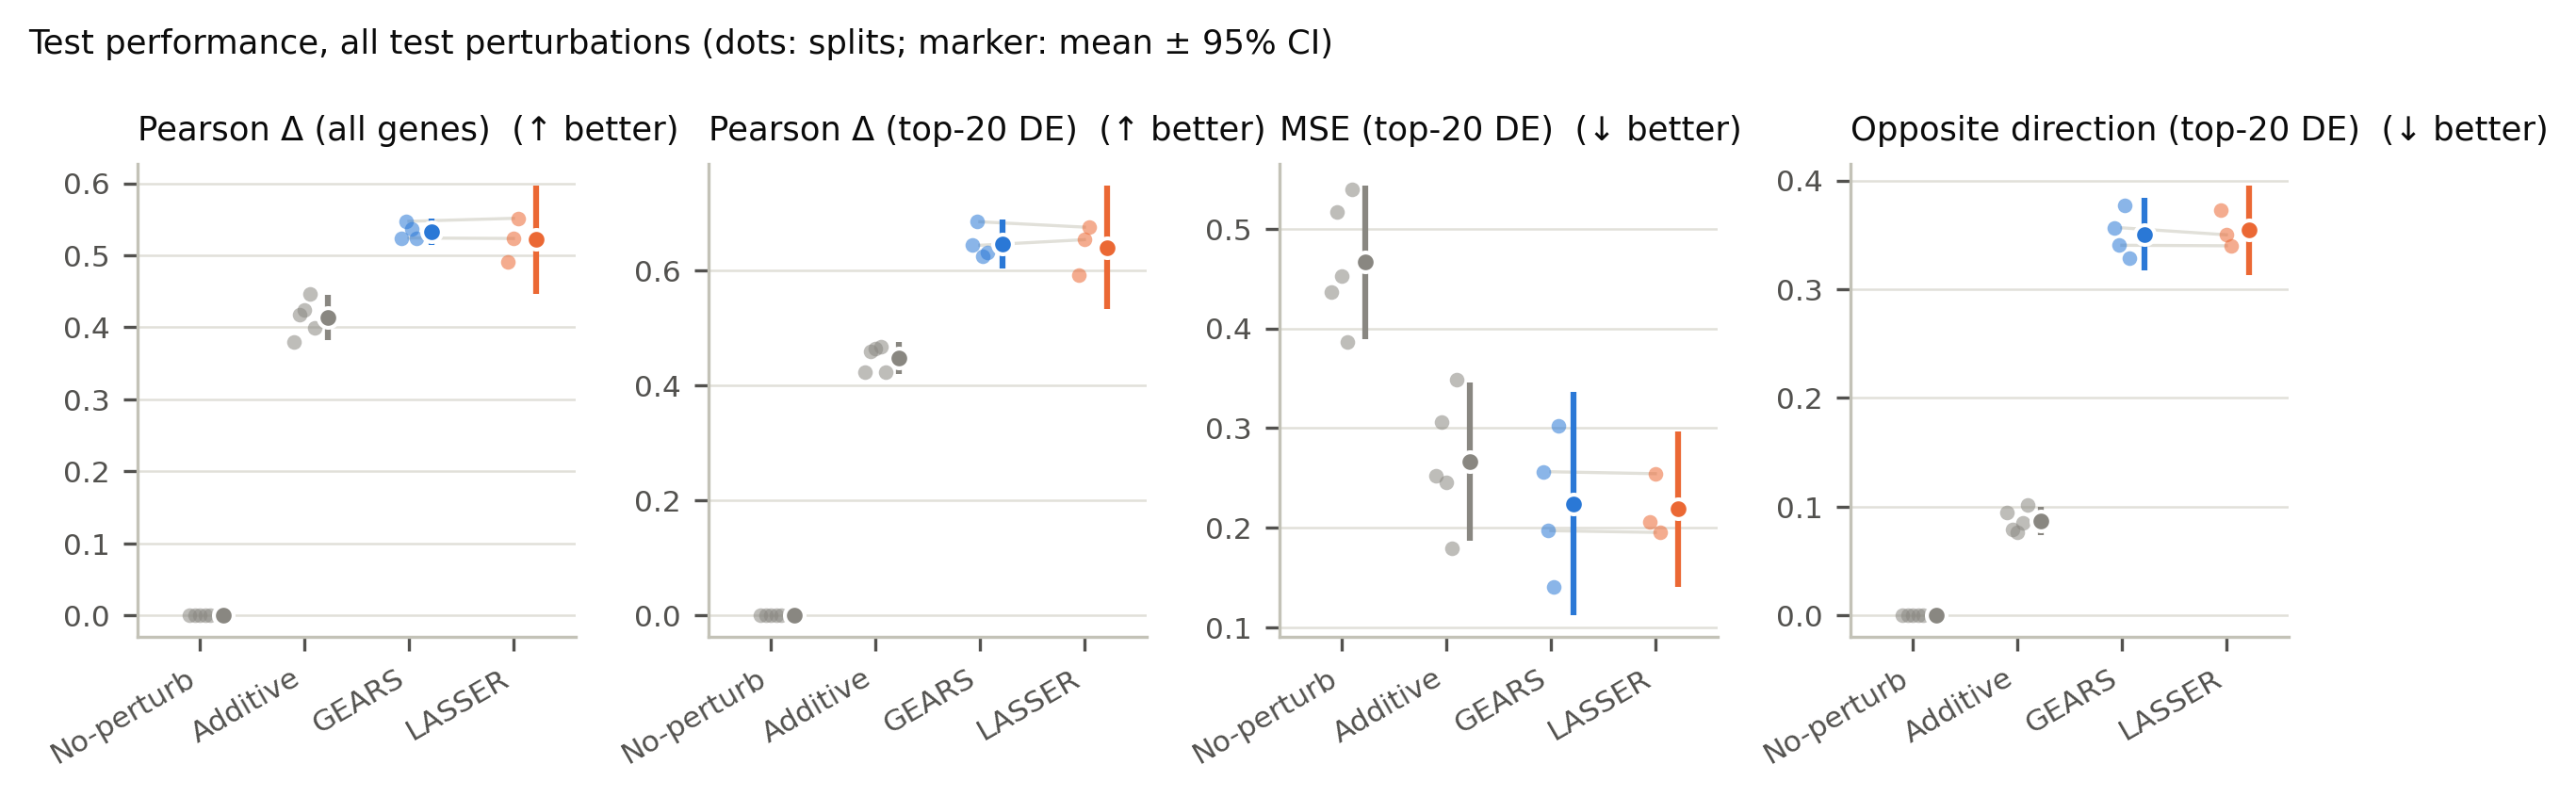

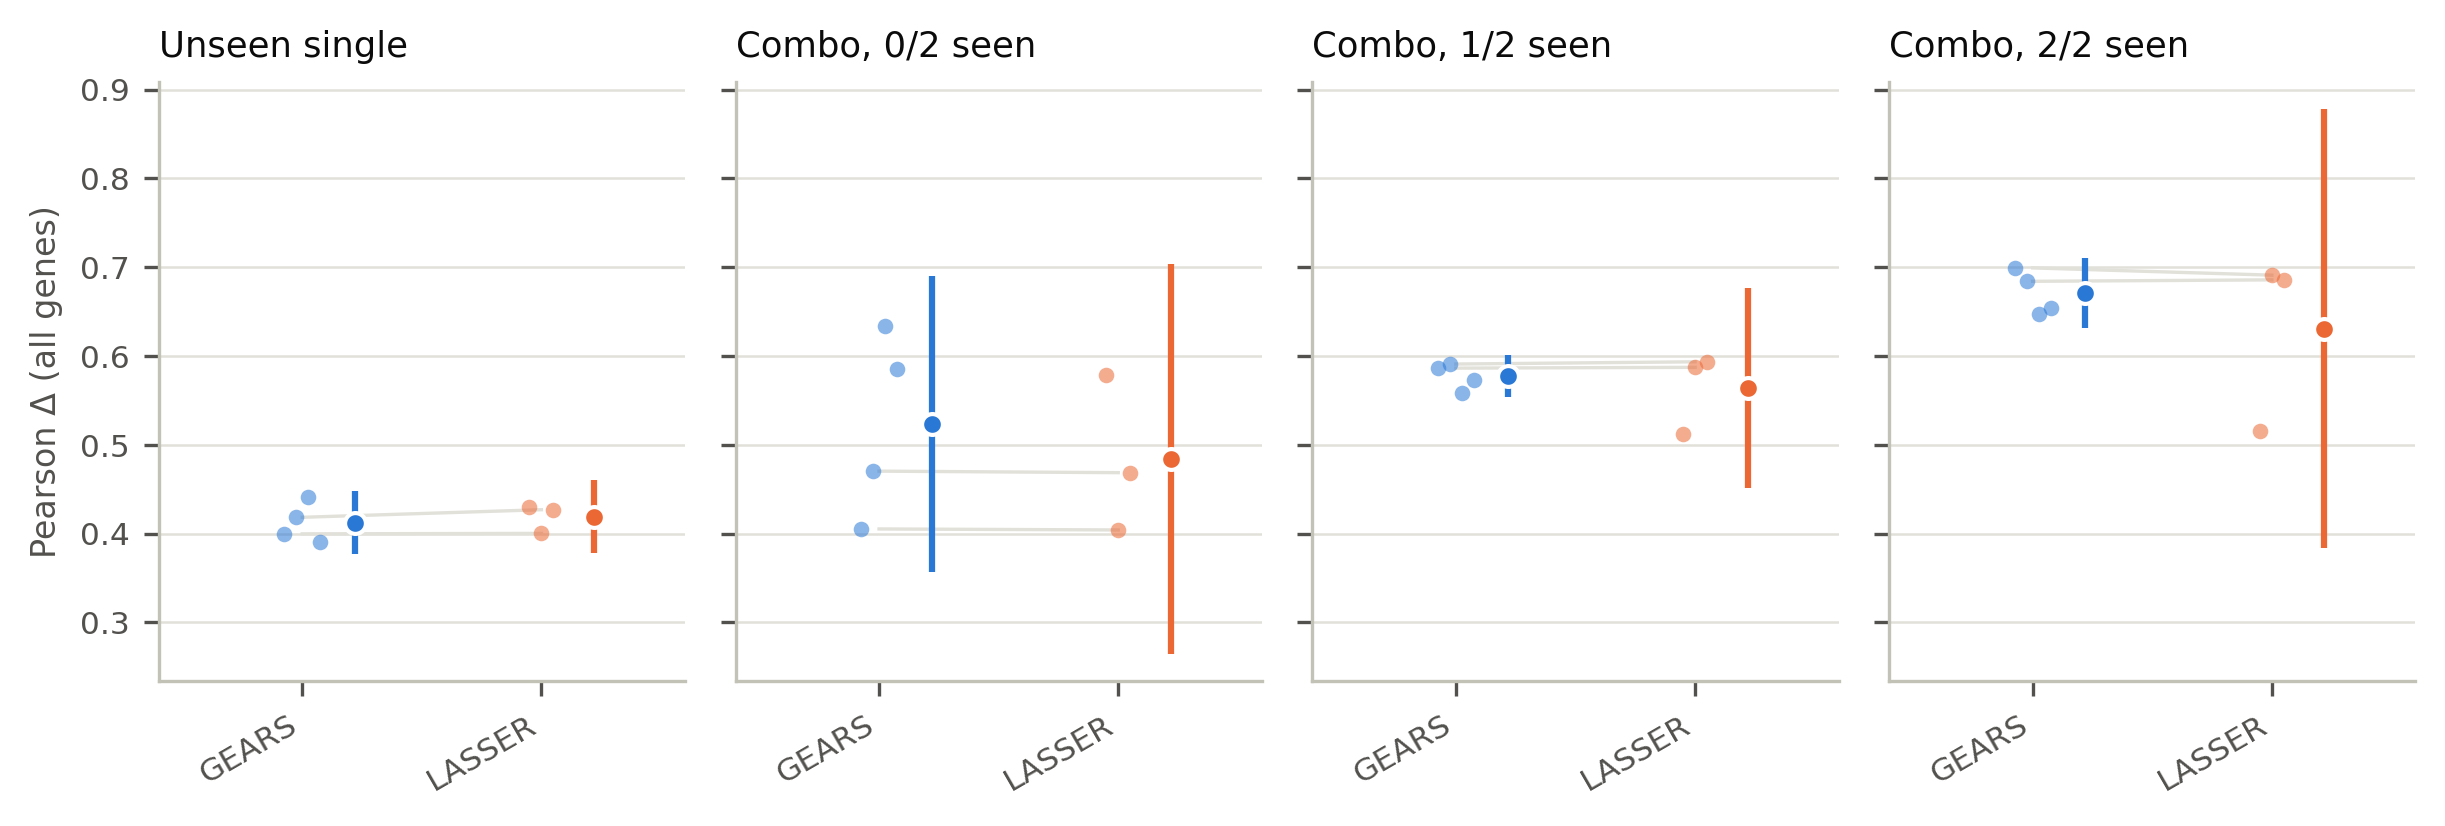

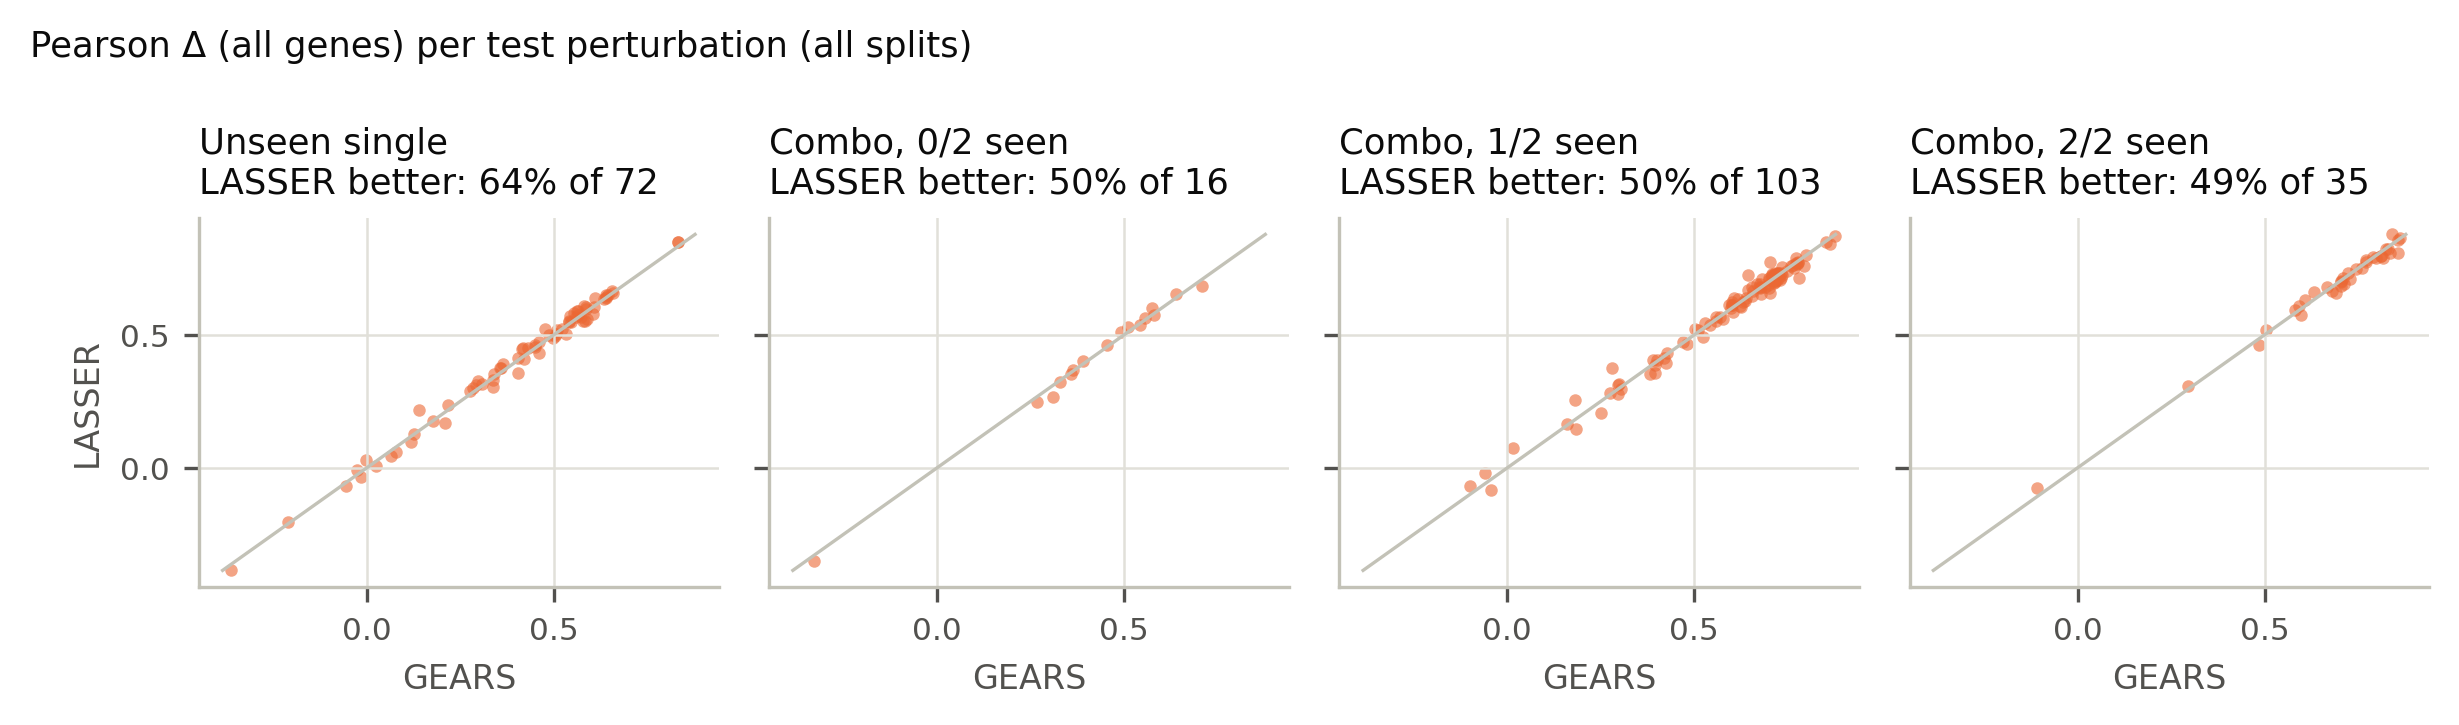

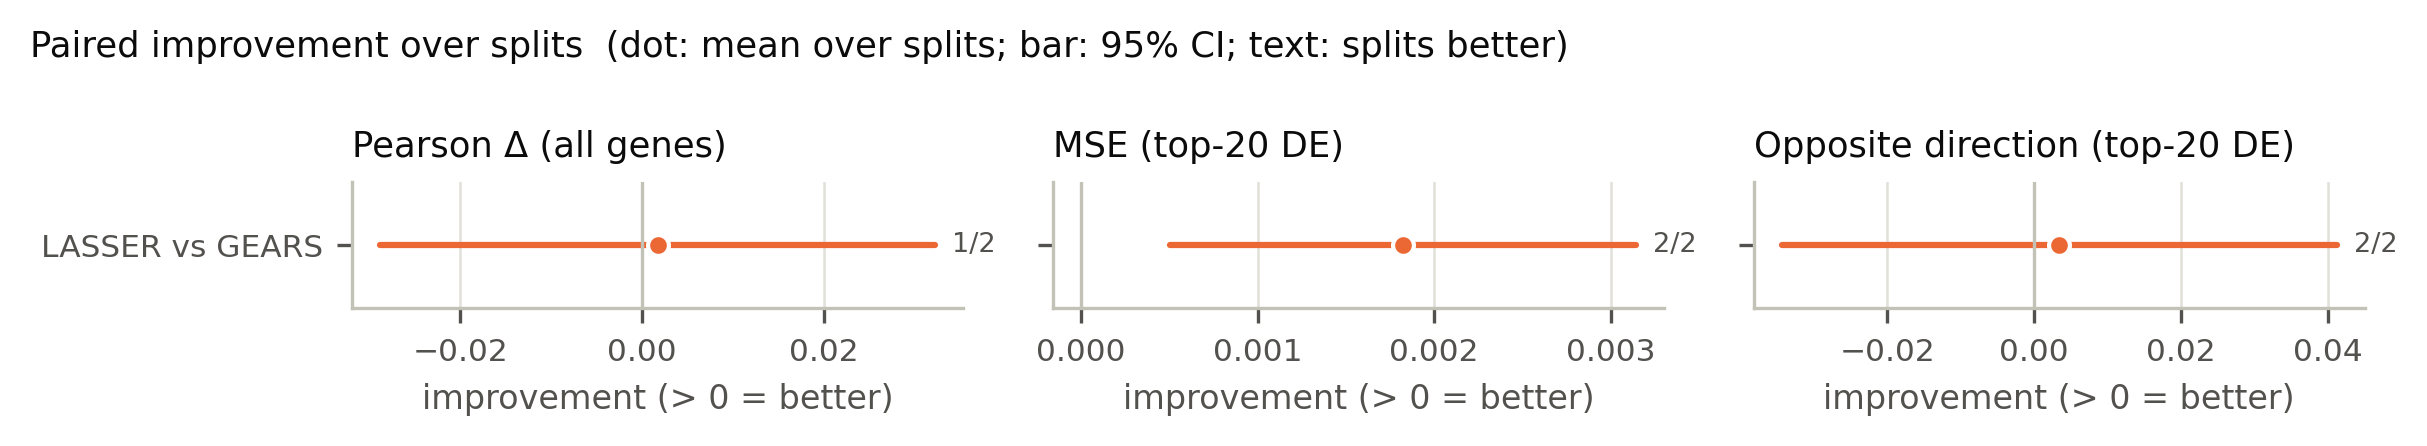

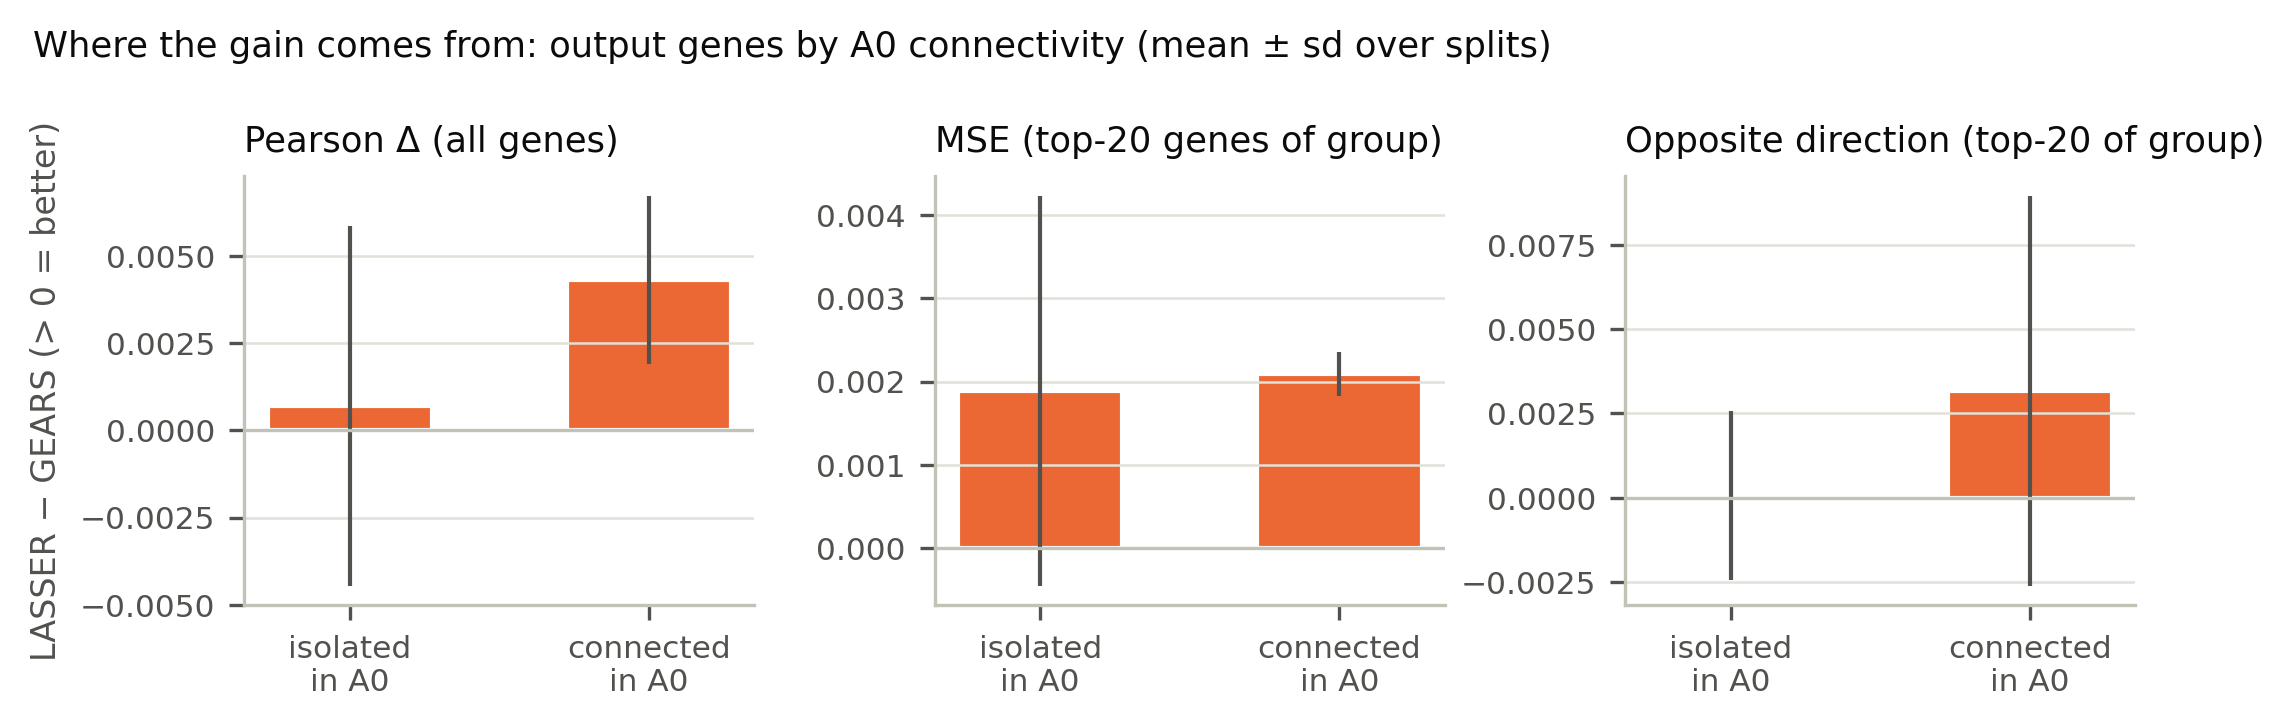

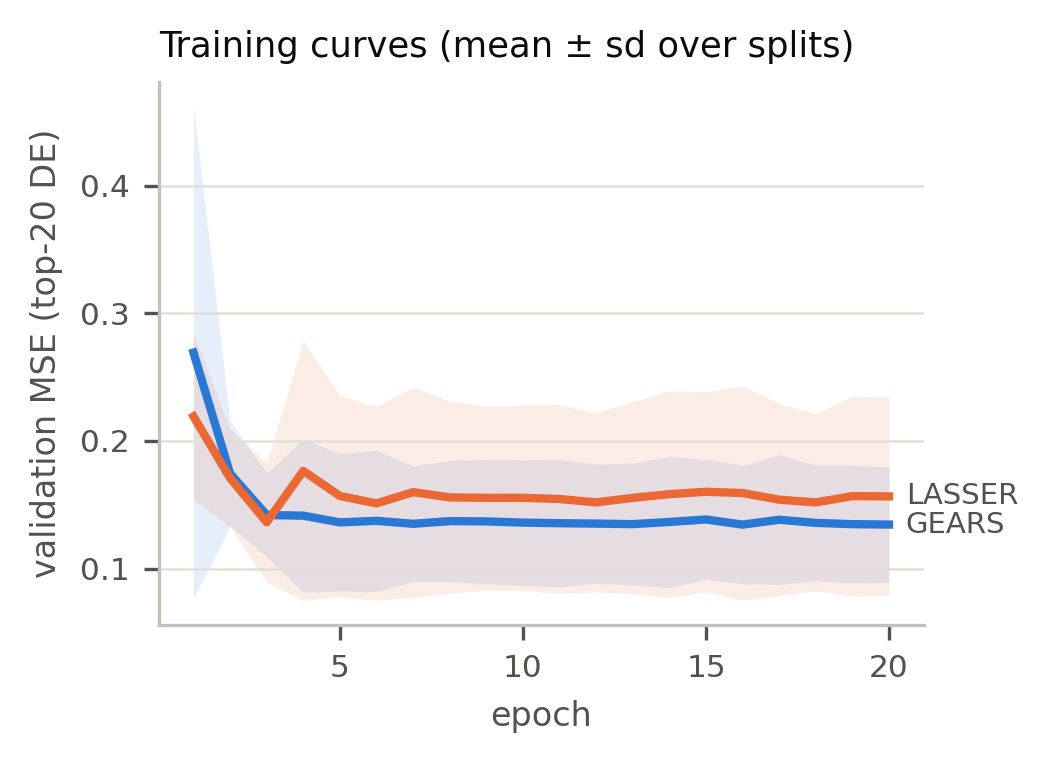

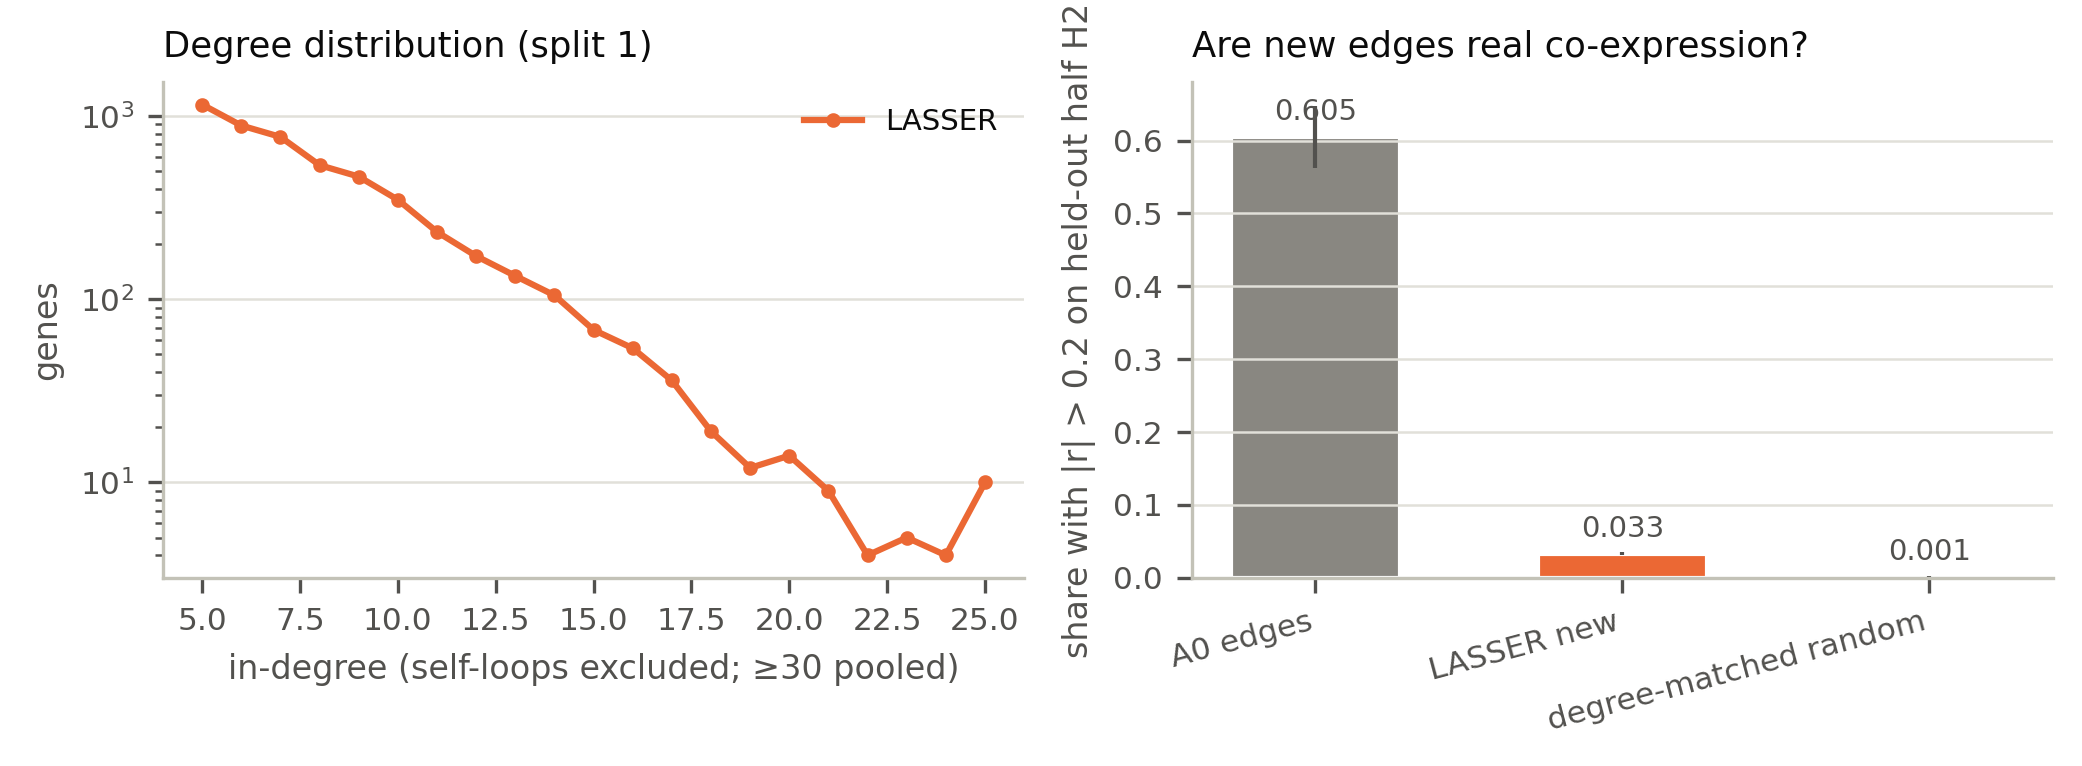

In [15]:
# 15. Figures (PDF + PNG in study/figures).
paths = []
paths += F.fig_headline(long, REFS + CORE, FIG_DIR)
paths += F.fig_subgroups(long, CORE, FIG_DIR)
paths += F.fig_per_perturbation(pp, FIG_DIR)
paths += F.fig_forest(t2, FIG_DIR, "fig_forest_core", "Paired improvement over splits")
if len(t4):
    paths += F.fig_forest(t4, FIG_DIR, "fig_forest_ablations", "Ablations vs LASSER (splits 1-3)")
paths += F.fig_gene_groups(t5, FIG_DIR)
paths += F.fig_training(A.training_curves(runs), CORE, FIG_DIR)
paths += F.fig_graphs(gt, runs, FIG_DIR)
from IPython.display import Image, display as _d
for p in paths:
    if p.endswith(".png"):
        _d(Image(p, width=900))

In [16]:
# 16. Export tables (CSV + LaTeX) and pack results/figures/run tables into one zip for download.
A.export_tables({"table1_headline": t1, "table1_subgroups": t1_sub, "table2_paired_splits": t2,
                 "table3_paired_perturbations": t3, "table4_ablations": t4, "table5_gene_groups": t5,
                 "graph_stats": gt, "consensus_edges": consensus}, RESULTS_DIR)
shutil.copy(f"{STUDY_DIR}/runs/runs.csv", RESULTS_DIR)
!cd {STUDY_DIR} && zip -qr /kaggle/working/lasser_study_results.zip results figures runs/runs.csv runs/jobs.json
print("results:", sorted(os.listdir(RESULTS_DIR)))
print("download: /kaggle/working/lasser_study_results.zip")

results: ['consensus_edges.csv', 'consensus_edges.tex', 'graph_stats.csv', 'graph_stats.tex', 'runs.csv', 'table1_headline.csv', 'table1_headline.tex', 'table1_subgroups.csv', 'table1_subgroups.tex', 'table2_paired_splits.csv', 'table2_paired_splits.tex', 'table3_paired_perturbations.csv', 'table3_paired_perturbations.tex', 'table5_gene_groups.csv', 'table5_gene_groups.tex']
download: /kaggle/working/lasser_study_results.zip


## C. Reporting checklist

- Report every arm as **mean ± sd over the 5 splits**, the paired improvement with its 95 % CI, and the number of
  splits that improved (Table 2). With 5 splits, give the paired *t*-test *p* and say Wilcoxon cannot go below
  0.0625. Use Holm-corrected *p* when claiming significance across several metrics or subgroups.
- The **controls** carry the claim. `LASSER > GEARS` alone may be "more edges help". `LASSER > GEARS-kNN8`
  (same density, plain correlation) and `LASSER > LASSER-random` (same degrees and weights, random partners) show
  that the *learned* edges matter.
- Show the reference baselines (No-perturb, Additive for combinations) next to the models, as the GEARS paper does.
- Report the per-perturbation view (Table 3, Fig. 3): the share of test perturbations improved and the
  split-resampling bootstrap CI.
- Graph analysis (Fig. 6, consensus edges): H2 hit rate of new edges vs degree-matched random, stability across
  splits, and the overlap with the kNN Pearson graph. Consensus edges are the starting point for the
  "reasoning about gene relationships" section.
- Known limitation to state: GEARS's co-expression GNN passes messages only for the first cell of each batch
  (upstream implementation, kept unchanged for a fair comparison).